Dataset:
https://huggingface.co/datasets/McAuley-Lab/Amazon-Reviews-2023

In [ ]:
import os
from dotenv import load_dotenv
from huggingface_hub import login
from datasets import load_dataset
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm
import numpy as np
import random
from utils.items import Item
from utils.parser import parse
from utils.loaders import ItemLoader
from utils.dataset_push import push_to_hub
from collections import Counter
load_dotenv(override=True)

True

In [2]:
# Logging in to huggingface

hf_token = os.environ['HF_TOKEN']
login(hf_token, add_to_git_credential=True)

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


In [3]:
# loading amazon reviews dataset
dataset = load_dataset("McAuley-Lab/Amazon-Reviews-2023", "raw_meta_Appliances", split="full", trust_remote_code=True)
print(f"Number of Appliances: {len(dataset):,}")

`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'McAuley-Lab/Amazon-Reviews-2023' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.
Using the latest cached version of the dataset since McAuley-Lab/Amazon-Reviews-2023 couldn't be found on the Hugging Face Hub
Found the latest cached dataset configuration 'raw_meta_Appliances' at C:\Users\tanma\.cache\huggingface\datasets\McAuley-Lab___amazon-reviews-2023\raw_meta_Appliances\0.0.0\16b76e0823d73bb8cff1e9c5e3e37dbc46ae3daee380417ae141f5e67d3ea8e8 (last modified on Fri Aug 21 22:26:41 2026).


Number of Appliances: 94,327


In [4]:
dataset[5]

{'main_category': 'Tools & Home Improvement',
 'title': '1841N030 - Brown Aftermarket Replacement Stove Range Oven Drip Bowl Pan',
 'average_rating': 4.5,
 'rating_number': 7,
 'features': ['This is a Brand New Aftermarket Replacement Drip Bowl Pan',
  'Top Qualty Aftermarket Replacement Part!'],
 'description': ['This is a Brand New Aftermarket Replacement Drip Bowl Pan'],
 'price': 'None',
 'images': {'hi_res': [None],
  'large': ['https://m.media-amazon.com/images/I/51HP3jWvtHL._AC_.jpg'],
  'thumb': ['https://m.media-amazon.com/images/I/51HP3jWvtHL._AC_US75_.jpg'],
  'variant': ['MAIN']},
 'videos': {'title': [], 'url': [], 'user_id': []},
 'store': 'Brown',
 'categories': ['Appliances',
  'Parts & Accessories',
  'Range Parts & Accessories',
  'Drip Pans'],
 'details': '{"Manufacturer": "Universal", "Part Number": "1841N030", "Item Weight": "3 ounces", "Product Dimensions": "6 x 6 x 6 inches", "Item model number": "CECOMINOD023154", "Is Discontinued By Manufacturer": "No", "Item P

In [5]:
# most expensive item

max_price = 0
max_item = None

for datapoint in tqdm(dataset):
    try:
        price = float(datapoint["price"])
        if price > max_price:
            max_item = datapoint
            max_price = price
    except ValueError:
        pass

print(f"most expensive item: {max_item['title']}\nPrice: {max_price:,.2f}")

  0%|          | 0/94327 [00:00<?, ?it/s]

most expensive item: TurboChef BULLET Rapid Cook Electric Microwave Convection Oven
Price: 21,095.62


In [6]:
# loading the products into Item object using the defined 'parse' function in utils

items = [parse(datapoint, "Appliances") for datapoint in tqdm(dataset)]
items = [item for item in items if item is not None]
print(f"{len(items):,} items from {len(dataset):,} datapoints")

  0%|          | 0/94327 [00:00<?, ?it/s]

35,325 items from 94,327 datapoints


In [7]:
print(items[6])

title='SAMSUNG DA97-11092B Genuine OEM Ice Maker Assembly for SAMSUNG Refrigerators' category='Appliances' price=138.0 full='DA97-11092B Genuine OEM Ice Maker Assembly for SAMSUNG Refrigerators\n[\'This high quality Genuine OEM Samsung Ice Maker Assembly (DA97-11092B) includes the ice mold and the control device. The Ice Maker Assembly . Repair your appliance with confidence when you choose Genuine Samsung Factory Parts & Accessories. Please be aware that it is recommended to disconnect the appliance from all utilities prior to installation of the Ice Maker Assembly.\']\n[\'The Samsung DA97-11092B Ice Maker Assembly is a genuine OEM (Original Equipment Manufacturer) part designed and engineered to exact specifications\', \'Replacement Samsung Refrigerator Ice Maker Assembly includes the ice mold and the control device\', \'Samsung DA97-11092B Refrigerator Ice Maker Assembly with approximate measurements of L: 11.5" x W: 5.5" x H: 5"\', \'High quality Samsung OEM DA97-11092B Refrigerato

In [8]:
print(items[6].full)

DA97-11092B Genuine OEM Ice Maker Assembly for SAMSUNG Refrigerators
['This high quality Genuine OEM Samsung Ice Maker Assembly (DA97-11092B) includes the ice mold and the control device. The Ice Maker Assembly . Repair your appliance with confidence when you choose Genuine Samsung Factory Parts & Accessories. Please be aware that it is recommended to disconnect the appliance from all utilities prior to installation of the Ice Maker Assembly.']
['The Samsung DA97-11092B Ice Maker Assembly is a genuine OEM (Original Equipment Manufacturer) part designed and engineered to exact specifications', 'Replacement Samsung Refrigerator Ice Maker Assembly includes the ice mold and the control device', 'Samsung DA97-11092B Refrigerator Ice Maker Assembly with approximate measurements of L: 11.5" x W: 5.5" x H: 5"', 'High quality Samsung OEM DA97-11092B Refrigerator Ice Maker Assembly is manufactured with premium materials for durability and exact fit, be sure to follow instructions in owners manua

Exploring the data

In [9]:
prices = [item.price for item in items]
lengths = [len(item.full) for item in items]

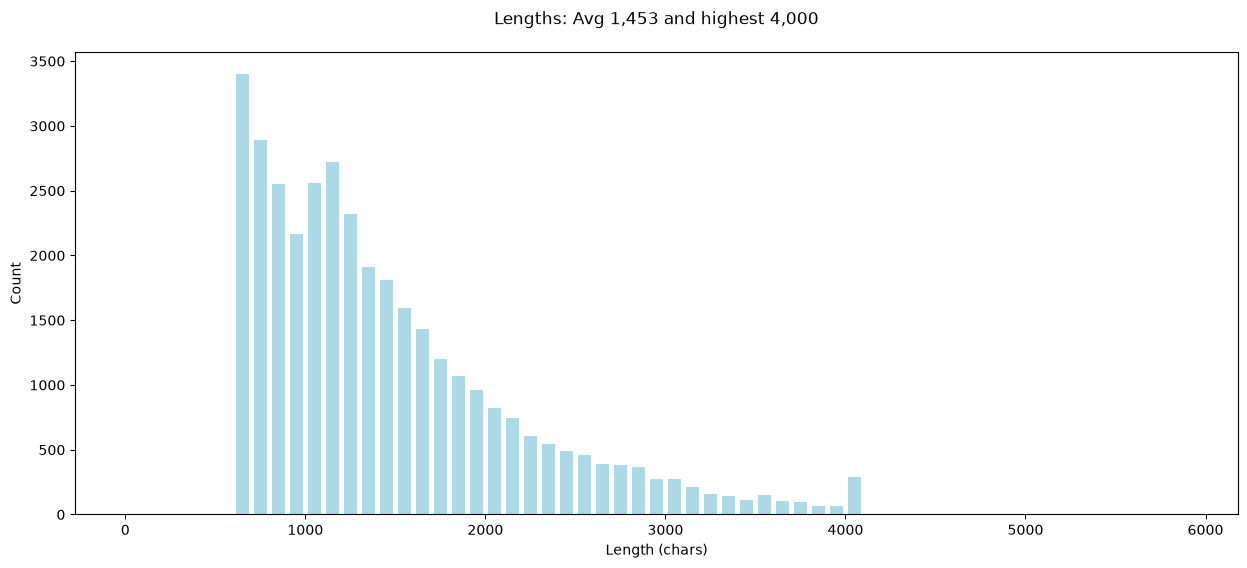

In [10]:
# plotting the distribution of description length

plt.figure(figsize=(15, 6))
plt.title(f"Lengths: Avg {sum(lengths)/len(lengths):,.0f} and highest {max(lengths):,}\n")
plt.xlabel('Length (chars)')
plt.ylabel('Count')
plt.hist(lengths, rwidth=0.7, color="lightblue", bins=range(0, 6000, 100))
plt.show()

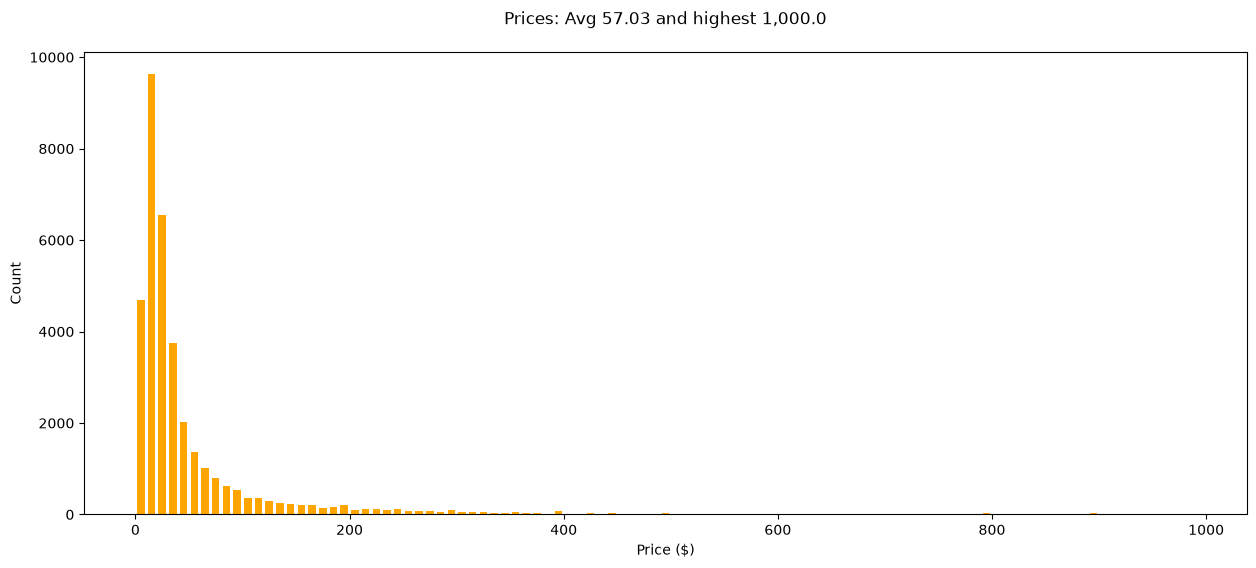

In [11]:
# plotting the distribution of prices

plt.figure(figsize=(15, 6))
plt.title(f"Prices: Avg {sum(prices)/len(prices):,.2f} and highest {max(prices):,}\n")
plt.xlabel('Price ($)')
plt.ylabel('Count')
plt.hist(prices, rwidth=0.7, color="orange", bins=range(0, 1000, 10))
plt.show()

In [12]:
# loading in items from appliances dataset
loader = ItemLoader("Appliances")
items = loader.load()

Loading dataset Appliances


Using the latest cached version of the dataset since McAuley-Lab/Amazon-Reviews-2023 couldn't be found on the Hugging Face Hub
Found the latest cached dataset configuration 'raw_meta_Appliances' at C:\Users\tanma\.cache\huggingface\datasets\McAuley-Lab___amazon-reviews-2023\raw_meta_Appliances\0.0.0\16b76e0823d73bb8cff1e9c5e3e37dbc46ae3daee380417ae141f5e67d3ea8e8 (last modified on Fri Aug 21 22:26:41 2026).
100%|██████████| 95/95 [00:04<00:00, 20.43it/s]


Completed Appliances with 35,325 datapoints in 0.1 mins


In [13]:
dataset_names = [
    "Automotive",
    "Electronics",
    "Office_Products",
    "Tools_and_Home_Improvement",
    "Cell_Phones_and_Accessories",
    "Toys_and_Games",
    "Appliances",
    "Musical_Instruments",
]

In [14]:
items = []
for dataset_name in dataset_names:
    loader = ItemLoader(dataset_name)
    items.extend(loader.load())

Loading dataset Automotive


Using the latest cached version of the dataset since McAuley-Lab/Amazon-Reviews-2023 couldn't be found on the Hugging Face Hub
Found the latest cached dataset configuration 'raw_meta_Automotive' at C:\Users\tanma\.cache\huggingface\datasets\McAuley-Lab___amazon-reviews-2023\raw_meta_Automotive\0.0.0\16b76e0823d73bb8cff1e9c5e3e37dbc46ae3daee380417ae141f5e67d3ea8e8 (last modified on Fri Aug 21 23:04:59 2026).
100%|██████████| 2004/2004 [02:39<00:00, 12.57it/s]


Completed Automotive with 974,562 datapoints in 3.0 mins
Loading dataset Electronics


Using the latest cached version of the dataset since McAuley-Lab/Amazon-Reviews-2023 couldn't be found on the Hugging Face Hub
Found the latest cached dataset configuration 'raw_meta_Electronics' at C:\Users\tanma\.cache\huggingface\datasets\McAuley-Lab___amazon-reviews-2023\raw_meta_Electronics\0.0.0\16b76e0823d73bb8cff1e9c5e3e37dbc46ae3daee380417ae141f5e67d3ea8e8 (last modified on Fri Aug 21 23:38:47 2026).
100%|██████████| 1611/1611 [02:11<00:00, 12.25it/s]


Completed Electronics with 464,258 datapoints in 2.4 mins
Loading dataset Office_Products


...

Completed Toys_and_Games with 347,683 datapoints in 1.1 mins
Loading dataset Appliances


Using the latest cached version of the dataset since McAuley-Lab/Amazon-Reviews-2023 couldn't be found on the Hugging Face Hub
Found the latest cached dataset configuration 'raw_meta_Appliances' at C:\Users\tanma\.cache\huggingface\datasets\McAuley-Lab___amazon-reviews-2023\raw_meta_Appliances\0.0.0\16b76e0823d73bb8cff1e9c5e3e37dbc46ae3daee380417ae141f5e67d3ea8e8 (last modified on Fri Aug 21 22:26:41 2026).
100%|██████████| 95/95 [00:05<00:00, 17.53it/s]


Completed Appliances with 35,325 datapoints in 0.1 mins
Loading dataset Musical_Instruments


Using the latest cached version of the dataset since McAuley-Lab/Amazon-Reviews-2023 couldn't be found on the Hugging Face Hub
Found the latest cached dataset configuration 'raw_meta_Musical_Instruments' at C:\Users\tanma\.cache\huggingface\datasets\McAuley-Lab___amazon-reviews-2023\raw_meta_Musical_Instruments\0.0.0\16b76e0823d73bb8cff1e9c5e3e37dbc46ae3daee380417ae141f5e67d3ea8e8 (last modified on Sun Aug 23 18:09:13 2026).
100%|██████████| 214/214 [00:08<00:00, 24.46it/s]


Completed Musical_Instruments with 68,930 datapoints in 0.2 mins


In [15]:
print(f"Loaded a grand total of {len(items):,} items")

Loaded a grand total of 2,934,110 items


In [16]:
random.seed(42)
random.shuffle(items)

# deleting items with duplicate title or description

seen = set()
items = [x for x in tqdm(items) if not (x.title in seen or seen.add(x.title))]

seen = set()
items = [x for x in tqdm(items) if not (x.full in seen or seen.add(x.full))]

del seen
print(f"After deduplication, we have {len(items):,} items")

  0%|          | 0/2934110 [00:00<?, ?it/s]

  0%|          | 0/2889953 [00:00<?, ?it/s]

After deduplication, we have 2,888,414 items


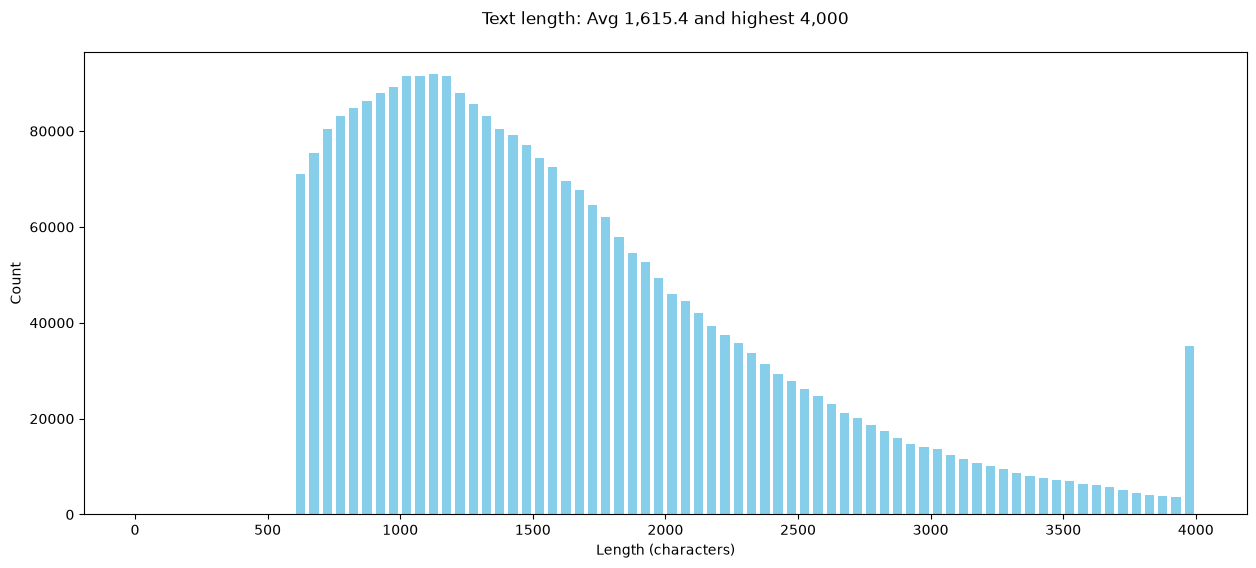

In [17]:
# plotting distribution of description lengths of all loaded items

lengths = [len(item.full) for item in items]
plt.figure(figsize=(15, 6))
plt.title(f"Text length: Avg {sum(lengths)/len(lengths):,.1f} and highest {max(lengths):,}\n")
plt.xlabel('Length (characters)')
plt.ylabel('Count')
plt.hist(lengths, rwidth=0.7, color="skyblue", bins=range(0, 4050, 50))
plt.show()

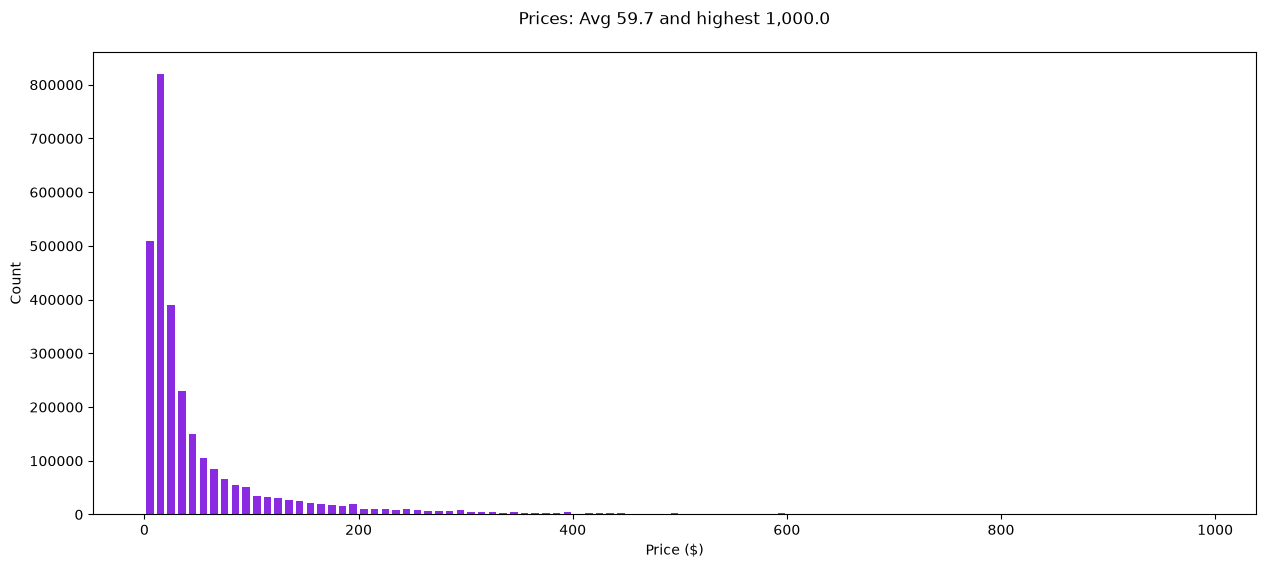

In [18]:
# plotting distribution of prices of all loaded items

prices = [item.price for item in items]
plt.figure(figsize=(15, 6))
plt.title(f"Prices: Avg {sum(prices)/len(prices):,.1f} and highest {max(prices):,}\n")
plt.xlabel('Price ($)')
plt.ylabel('Count')
plt.hist(prices, rwidth=0.7, color="blueviolet", bins=range(0, 1000, 10))
plt.show()

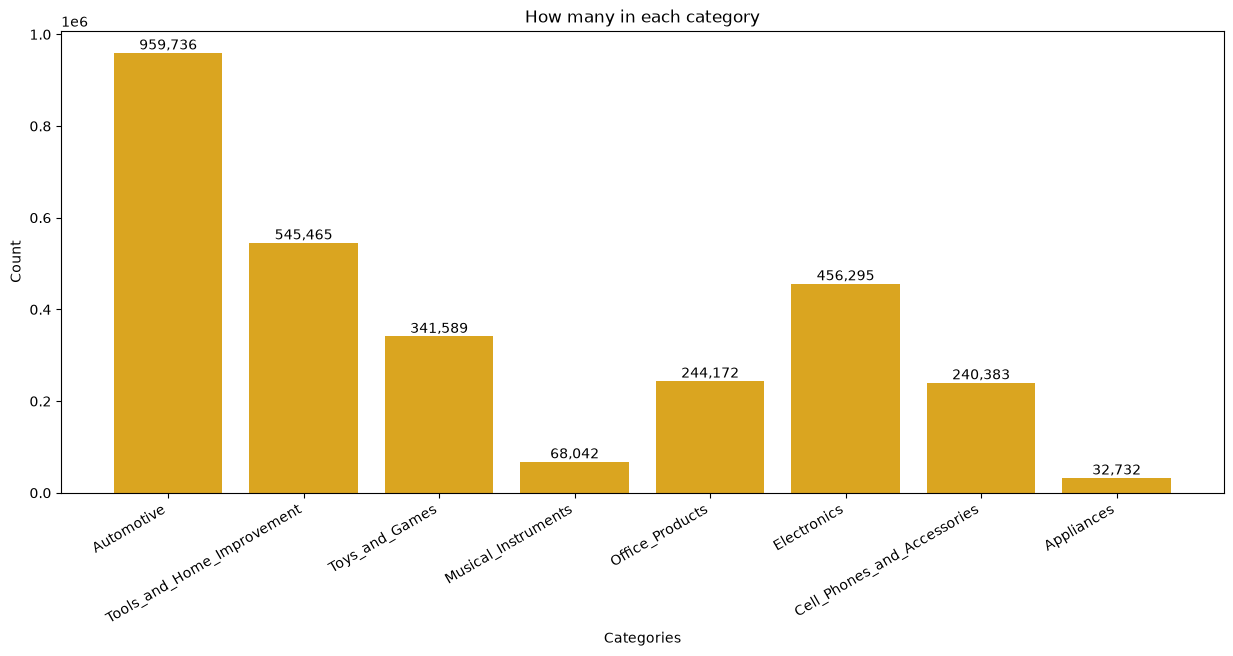

In [19]:
# checking count of items in each category

category_counts = Counter([item.category for item in items])

categories = category_counts.keys()
counts = [category_counts[category] for category in categories]

plt.figure(figsize=(15, 6))
plt.bar(categories, counts, color="goldenrod")
plt.title('How many in each category')
plt.xlabel('Categories')
plt.ylabel('Count')
plt.xticks(rotation=30, ha='right')

for i, v in enumerate(counts):
    plt.text(i, v, f"{v:,}", ha='center', va='bottom')

plt.show()

as observed in the category distribution, we can see that there are  a lot of items in 'Tools and home improvement' and 'automotive', and a lot of cheap products, which results in the dataset being skewed to these categories. So we decide to sub-select a population of items from these big distributions

In [20]:
np.random.seed(42)

SIZE = 820_000

prices = np.array([it.price for it in items], dtype=float)
categories = np.array([it.category for it in items])
p = (prices - prices.min()) / (prices.max() - prices.min() + 1e-9)

w = p**2
w[categories == "Tools_and_Home_Improvement"] *= 0.5
w[categories == "Automotive"] *= 0.05

w = w / w.sum()
idx = np.random.choice(len(items), size=SIZE, replace=False, p=w)
sample = [items[i] for i in idx]


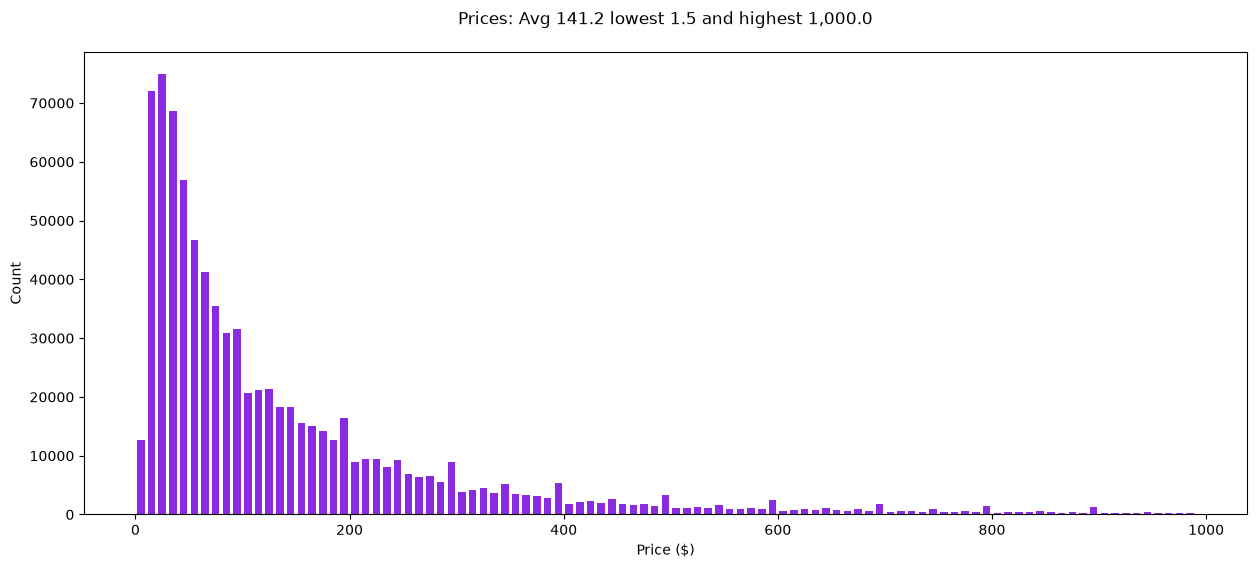

In [21]:
prices = [item.price for item in sample]
plt.figure(figsize=(15, 6))
plt.title(f"Prices: Avg {sum(prices)/len(prices):,.1f} lowest {min(prices):,} and highest {max(prices):,}\n")
plt.xlabel('Price ($)')
plt.ylabel('Count')
plt.hist(prices, rwidth=0.7, color="blueviolet", bins=range(0, 1000, 10))
plt.show()

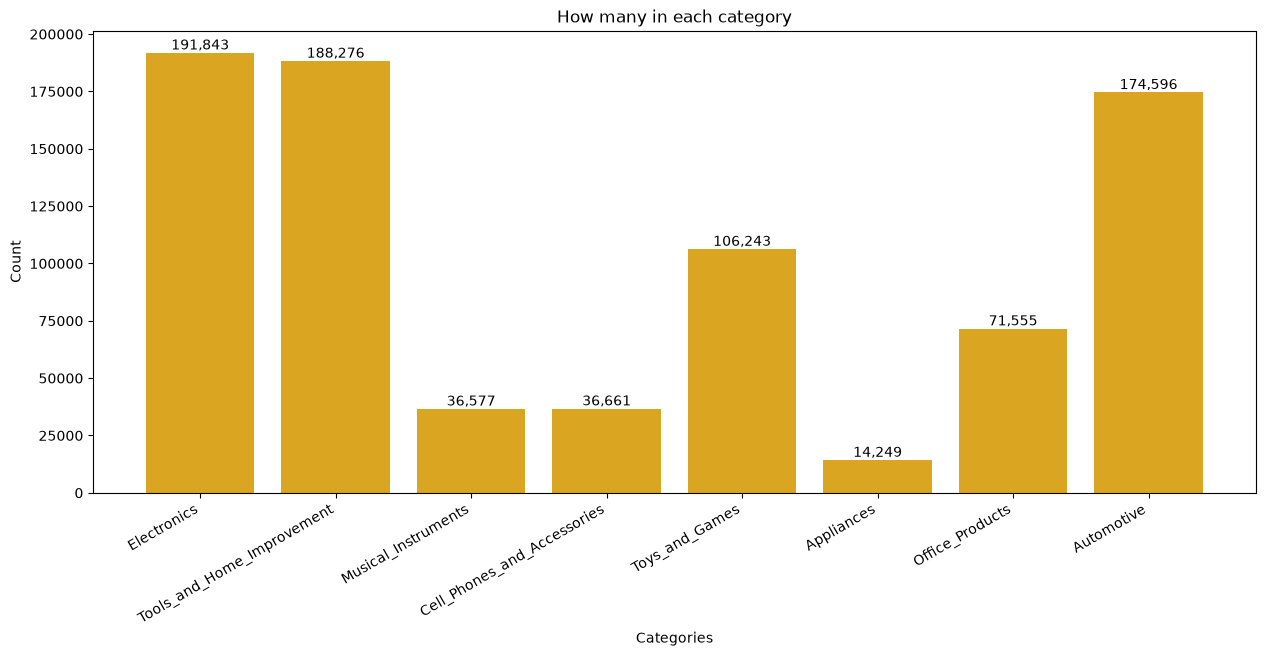

In [22]:
# checking count of items in each category after sub-selection

category_counts = Counter([item.category for item in sample])

categories = category_counts.keys()
counts = [category_counts[category] for category in categories]

plt.figure(figsize=(15, 6))
plt.bar(categories, counts, color="goldenrod")
plt.title('How many in each category')
plt.xlabel('Categories')
plt.ylabel('Count')

plt.xticks(rotation=30, ha='right')

for i, v in enumerate(counts):
    plt.text(i, v, f"{v:,}", ha='center', va='bottom')

# Display the chart
plt.show()

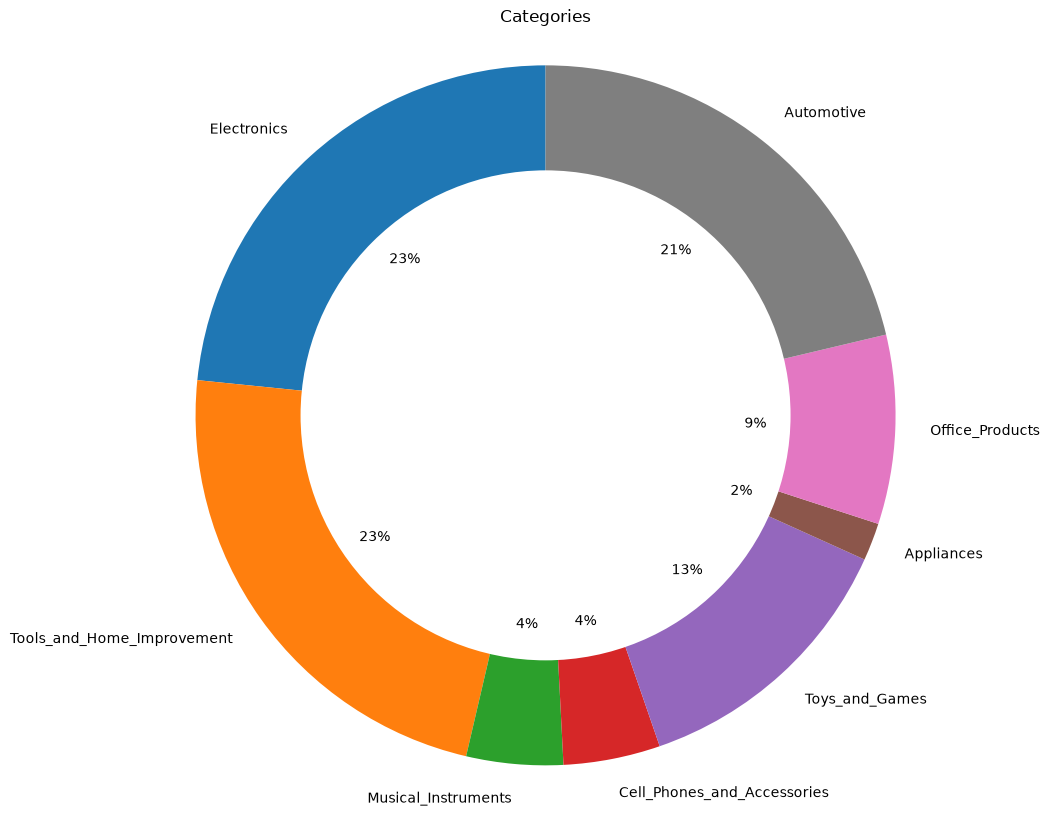

In [23]:
# Automotive still in the lead, but improved somewhat

plt.figure(figsize=(12, 10))
plt.pie(counts, labels=categories, autopct='%1.0f%%', startangle=90)

# Add a circle at the center to create a donut chart (optional)
centre_circle = plt.Circle((0,0), 0.70, fc='white')
fig = plt.gcf()
fig.gca().add_artist(centre_circle)
plt.title('Categories')

# Equal aspect ratio ensures that pie is drawn as a circle
plt.axis('equal')  

plt.show()

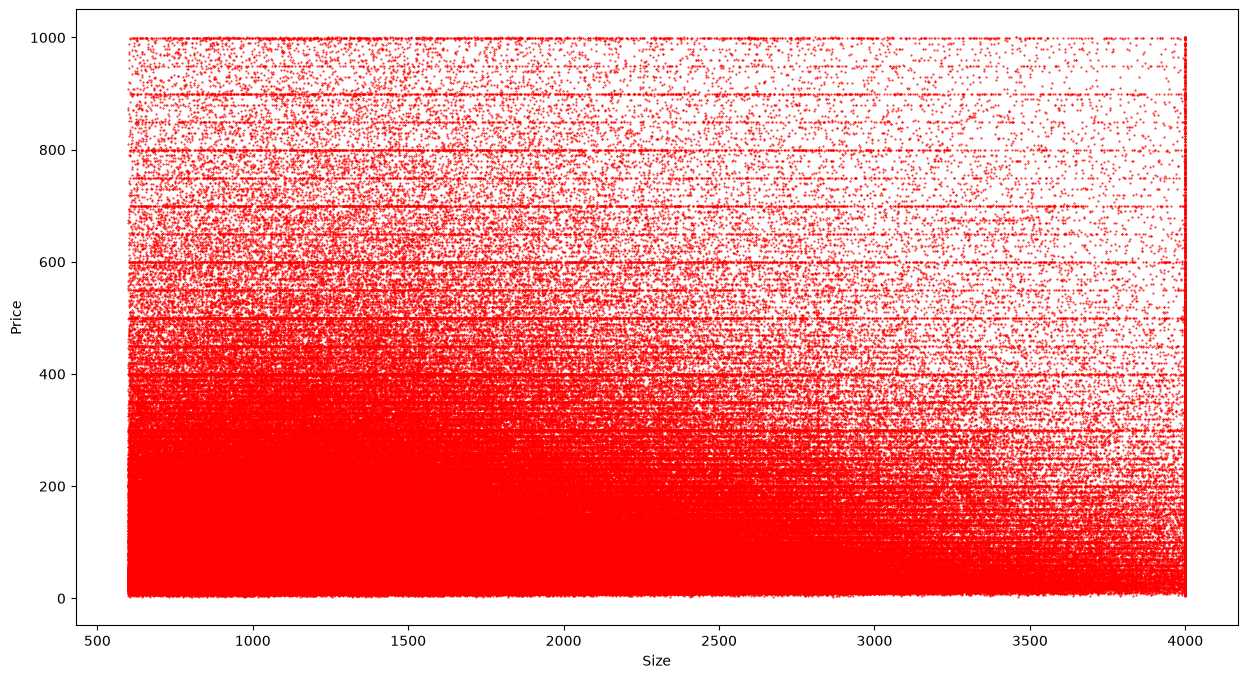

In [24]:
# checking if there is any correlation between price and description character count

sizes = [len(item.full) for item in sample]
prices = [item.price for item in sample]

# Create the scatter plot
plt.figure(figsize=(15, 8))
plt.scatter(sizes, prices, s=0.2, color="red")

# Add labels and title
plt.xlabel('Size')
plt.ylabel('Price')

# Display the plot
plt.show()

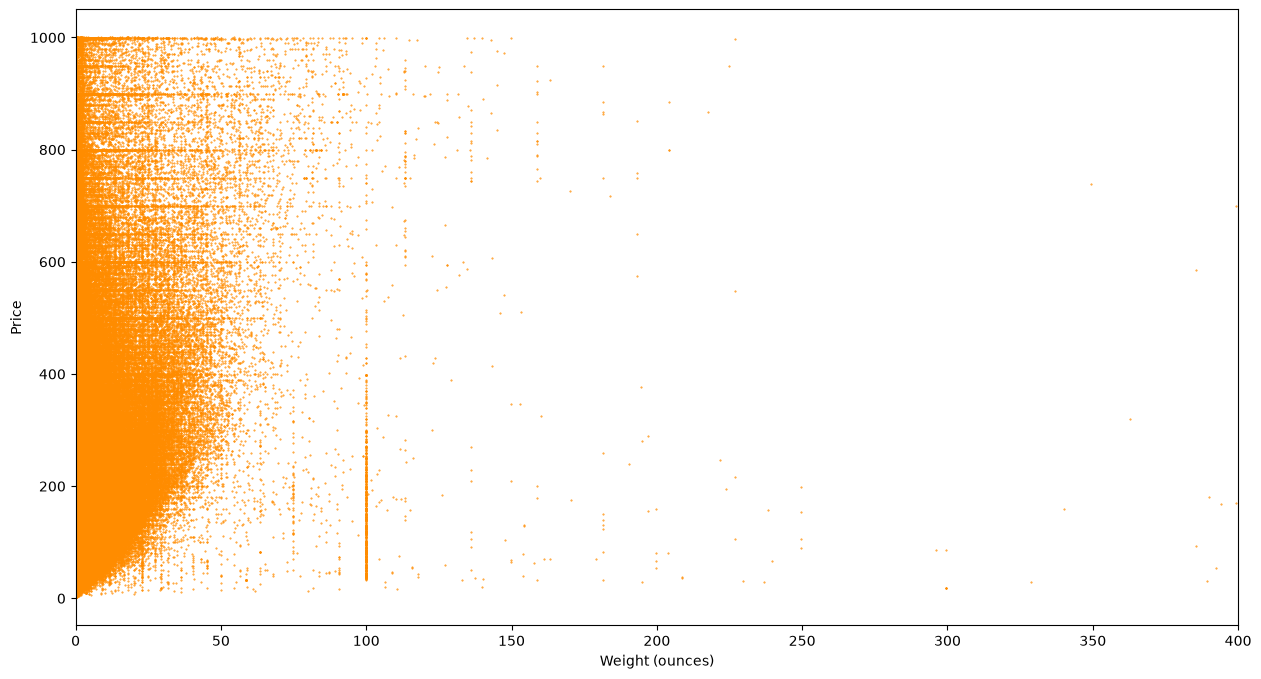

In [25]:
# checking if there is any correlation between the weight and price

ounces = [item.weight for item in sample]
prices = [item.price for item in sample]

# Create the scatter plot
plt.figure(figsize=(15, 8))
plt.scatter(ounces, prices, s=0.2, color="darkorange")

# Add labels and title
plt.xlabel('Weight (ounces)')
plt.ylabel('Price')
plt.xlim(0, 400)

# Display the plot
plt.show()

Pushing the dataset to huggingface

In [26]:
username = "fluorospekk"
full = f"{username}/items_raw_full"
lite = f"{username}/items_raw_lite"

train = sample[:800_000]
val = sample[800_000:810_000]
test = sample[810_000:]

push_to_hub(full, train, val, test)

train_lite = train[:20_000]
val_lite = val[:1_000]
test_lite = test[:1_000]

push_to_hub(lite, train_lite, val_lite, test_lite)

Uploading the dataset shards:   0%|          | 0/3 [00:00<?, ? shards/s]

Creating parquet from Arrow format:   0%|          | 0/5 [00:00<?, ?ba/s]

Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

Validating:           |   0%            

...

Uploading the dataset shards:   0%|          | 0/1 [00:00<?, ? shards/s]

Creating parquet from Arrow format:   0%|          | 0/1 [00:00<?, ?ba/s]

Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

Validating:           |   0%            